Since we're forecasting future demand, we split the dataset chronologically.
Model 1: Linear Regression
Learn a relationship between calendar features, store location, historical sales, and hourly demand.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load processed data
model_df = pd.read_csv(
    "../data/processed/model_data.csv",
    parse_dates=["transaction_date"]
)

print("Dataset shape:", model_df.shape)
print(model_df.head())

Dataset shape: (6164, 9)
  transaction_date store_location  hour  drinks_sold  day_of_week  is_weekend  \
0       2023-01-08        Astoria    11           14            6           1   
1       2023-01-08        Astoria    12           13            6           1   
2       2023-01-08        Astoria    13           20            6           1   
3       2023-01-08        Astoria    14           16            6           1   
4       2023-01-08        Astoria    15           15            6           1   

   month  sales_lag_1d  sales_lag_7d  
0      1          17.0          28.0  
1      1          26.0          38.0  
2      1          18.0          30.0  
3      1          12.0          21.0  
4      1          18.0          28.0  


In [3]:

#Chronological split
train_df = model_df[
    model_df["transaction_date"] < "2023-05-01"
].copy()

val_df = model_df[
    (model_df["transaction_date"] >= "2023-05-01") &
    (model_df["transaction_date"] < "2023-06-01")
].copy()

test_df = model_df[
    model_df["transaction_date"] >= "2023-06-01"
].copy()

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))


Training: 4005
Validation: 1099
Testing: 1060


In [7]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

#calculate average demand using TRAINING data only
store_hour_mean = (
    train_df.groupby(
        ["store_location", "hour"],
        as_index=False
    )["drinks_sold"]
    .mean()
    .rename(columns={"drinks_sold": "baseline_prediction"})
)

#match historical averages to validation observations
val_baseline = val_df[
    ["store_location", "hour"]
].merge(
    store_hour_mean,
    on=["store_location", "hour"],
    how="left",
    validate="many_to_one"
)

#fallback if a store-hour wasn't present in training
baseline_pred = val_baseline[
    "baseline_prediction"
].fillna(train_df["drinks_sold"].mean()).to_numpy()

#compare predicted vs actual sales
y_val = val_df["drinks_sold"].to_numpy()

baseline_mae = mean_absolute_error(y_val, baseline_pred)
baseline_rmse = np.sqrt(mean_squared_error(y_val, baseline_pred))

print("Baseline MAE:", round(baseline_mae, 2))
print("Baseline RMSE:", round(baseline_rmse, 2))


Baseline MAE: 14.46
Baseline RMSE: 19.97


MAE (Mean Absolute Error): how far our predictions are from actual sales on average
RMSE (Root Mean Squared Error): penalizes larger errors more heavily, useful when we want to avoid major forecasting mistakes during busy periods

In [10]:
#use one-hot encoding for hour, day_of_week, and store_location
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

categorical_features = [
    "store_location",
    "hour",
    "day_of_week"
]

numeric_features = [
    "month",
    "sales_lag_1d",
    "sales_lag_7d"
]

feature_columns = categorical_features + numeric_features

X_train = train_df[feature_columns]
y_train = train_df["drinks_sold"]

X_val = val_df[feature_columns]
y_val = val_df["drinks_sold"]

#convert categorical variables into numerical indicators
preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "num",
            "passthrough",
            numeric_features
        )
    ]
)

#preprocessing + ML model
linear_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

#train on January-April
linear_model.fit(X_train, y_train)

#predict May demand
linear_pred = linear_model.predict(X_val)

#beverage sales cannot be negative
linear_pred = np.maximum(linear_pred, 0)

linear_mae = mean_absolute_error(y_val, linear_pred)
linear_rmse = np.sqrt(mean_squared_error(y_val, linear_pred))

print("Linear Regression MAE:", round(linear_mae, 2))
print("Linear Regression RMSE:", round(linear_rmse, 2))


Linear Regression MAE: 10.08
Linear Regression RMSE: 14.13


In [12]:

import pandas as pd

comparison = pd.DataFrame({
    "Model": [
        "Historical Average",
        "Linear Regression"
    ],
    "MAE": [
        baseline_mae,
        linear_mae
    ],
    "RMSE": [
        baseline_rmse,
        linear_rmse
    ]
})

print(comparison.round(2).to_string(index=False))


             Model   MAE  RMSE
Historical Average 14.46 19.97
 Linear Regression 10.08 14.13


Our Linear Regression model predicts hourly beverage demand with an MAE of 10.08 drinks, compared with 14.46 for the historical-average baseline.
This is evidence that combining calendar information, store location, and historical sales improves predictions on our May validation data.
However, an average error of 10 drinks could still matter operationally, especially during quiet hours.

Now answer: Does our model follow actual demand patterns, or does it consistently overestimate or underestimate sales?

In [13]:

#combine actual sales with model predictions
val_results = val_df[
    ["transaction_date", "store_location", "hour", "drinks_sold"]
].reset_index(drop=True).copy()

val_results["baseline_pred"] = baseline_pred
val_results["linear_pred"] = linear_pred

#calculate absolute errors
val_results["baseline_error"] = abs(
    val_results["drinks_sold"] - val_results["baseline_pred"]
)

val_results["linear_error"] = abs(
    val_results["drinks_sold"] - val_results["linear_pred"]
)

print(val_results.head().to_string(index=False))


transaction_date store_location  hour  drinks_sold  baseline_pred  linear_pred  baseline_error  linear_error
      2023-05-01        Astoria    11           70      18.663717    22.203100       51.336283     47.796900
      2023-05-01        Astoria    12           64      19.072727    24.009043       44.927273     39.990957
      2023-05-01        Astoria    13           47      17.920354    29.127741       29.079646     17.872259
      2023-05-01        Astoria    14           36      17.548673    21.683620       18.451327     14.316380
      2023-05-01        Astoria    15           61      18.000000    26.211973       43.000000     34.788027


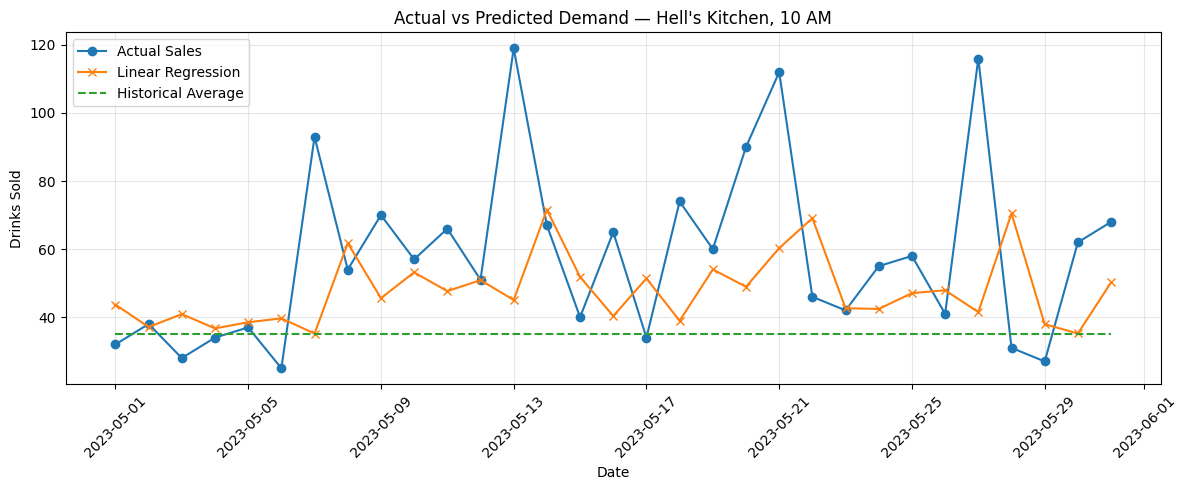

In [17]:

#select one store and hour
plot_df = val_results[
    (val_results["store_location"] == "Hell's Kitchen") &
    (val_results["hour"] == 10)
].sort_values("transaction_date")

plt.figure(figsize=(12, 5))

plt.plot(
    plot_df["transaction_date"],
    plot_df["drinks_sold"],
    marker="o",
    label="Actual Sales"
)

plt.plot(
    plot_df["transaction_date"],
    plot_df["linear_pred"],
    marker="x",
    label="Linear Regression"
)

plt.plot(
    plot_df["transaction_date"],
    plot_df["baseline_pred"],
    linestyle="--",
    label="Historical Average"
)

plt.title("Actual vs Predicted Demand — Hell's Kitchen, 10 AM")
plt.xlabel("Date")
plt.ylabel("Drinks Sold")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


Historical average: Predicts approximately 35 drinks every day. It cannot respond to day-to-day demand changes
Linear regression: Predictions vary between approximately 35 and 70 drinks, capturing some changes
Actual sales: Demand sometimes exceeds 110 drinks, far above the model's predictions

2 weaknesses:
1. Underprediction of demand spikes - When sales approach 120 drinks, Linear Regression sometimes predicts only 45–60
2. Overprediction on quieter days - On some days with approximately 30 actual drinks, the model predicts around 70

In [20]:

store_errors = (
    val_results.groupby("store_location")
    .agg(
        baseline_MAE=("baseline_error", "mean"),
        linear_MAE=("linear_error", "mean"),
        observations=("drinks_sold", "size")
    )
    .round(2)
)

print(store_errors.to_string())


                 baseline_MAE  linear_MAE  observations
store_location                                         
Astoria                 16.42       10.72           346
Hell's Kitchen          13.17       10.15           392
Lower Manhattan         13.98        9.38           361


In [23]:
#Monthly demand summary
monthly_demand = (
    model_df.assign(
        month=model_df["transaction_date"].dt.to_period("M")
    )
    .groupby("month")["drinks_sold"]
    .agg(["mean", "median", "count"])
)

print(monthly_demand.round(2).to_string())


          mean  median  count
month                        
2023-01  16.41    14.0    864
2023-02  18.18    16.0    985
2023-03  21.19    19.0   1100
2023-04  26.33    23.0   1056
2023-05  33.61    30.0   1099
2023-06  36.79    33.0   1060


Cafe beverage sales increased substantially between January and June 2023.

In [24]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

#use the same features as Linear Regression
rf_preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "num",
            "passthrough",
            numeric_features
        )
    ]
)

#build Random Forest pipeline
rf_model = Pipeline([
    ("preprocessor", rf_preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=200,
        max_depth=12,
        min_samples_leaf=4,
        random_state=42,
        n_jobs=-1
    ))
])

#train on January-April
rf_model.fit(X_train, y_train)

#predict May demand
rf_pred = rf_model.predict(X_val)

#ensure predictions are nonnegative
rf_pred = np.maximum(rf_pred, 0)

#evaluate
rf_mae = mean_absolute_error(y_val, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_val, rf_pred))

print("Random Forest MAE:", round(rf_mae, 2))
print("Random Forest RMSE:", round(rf_rmse, 2))


Random Forest MAE: 10.54
Random Forest RMSE: 14.73


In [27]:

comparison = pd.DataFrame({
    "Model": [
        "Historical Average",
        "Linear Regression",
        "Random Forest"
    ],
    "MAE": [
        baseline_mae,
        linear_mae,
        rf_mae
    ],
    "RMSE": [
        baseline_rmse,
        linear_rmse,
        rf_rmse
    ]
})

print(comparison.round(2).to_string(index=False))


             Model   MAE  RMSE
Historical Average 14.46 19.97
 Linear Regression 10.08 14.13
     Random Forest 10.54 14.73


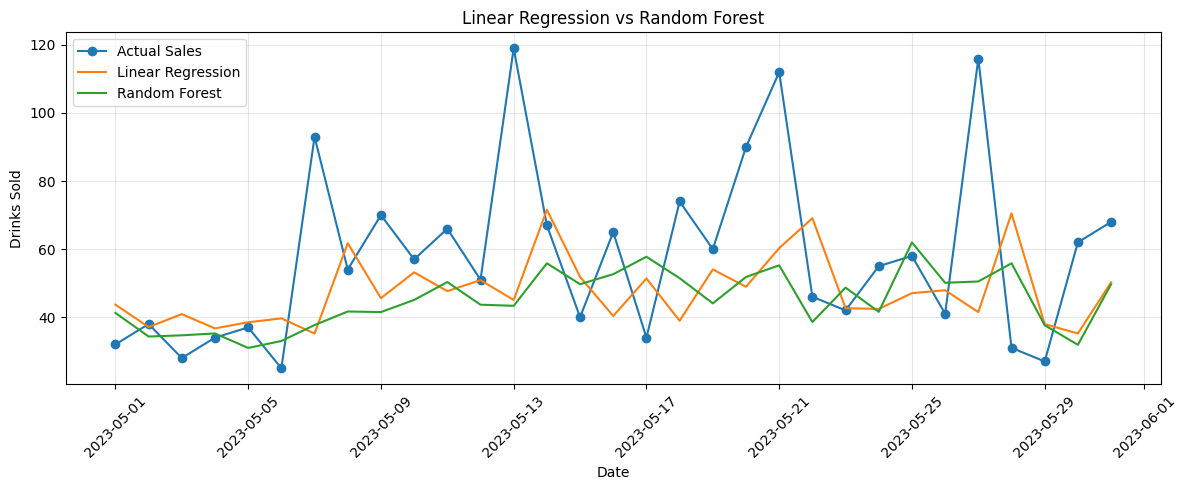

In [28]:

#add Random Forest predictions
val_results["rf_pred"] = rf_pred

plot_df = val_results[
    (val_results["store_location"] == "Hell's Kitchen") &
    (val_results["hour"] == 10)
].sort_values("transaction_date")

plt.figure(figsize=(12, 5))

plt.plot(
    plot_df["transaction_date"],
    plot_df["drinks_sold"],
    marker="o",
    label="Actual Sales"
)

plt.plot(
    plot_df["transaction_date"],
    plot_df["linear_pred"],
    label="Linear Regression"
)

plt.plot(
    plot_df["transaction_date"],
    plot_df["rf_pred"],
    label="Random Forest"
)

plt.title("Linear Regression vs Random Forest")
plt.xlabel("Date")
plt.ylabel("Drinks Sold")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


Current best model: Linear Regression 10.08 MAE
30.3% lower MAE than the historical-average baseline on May validation data.
Random Forest's MAE is approximately 4.6% higher than Linear Regression's.

In [29]:

#recent-sales baselines
y_val = val_df["drinks_sold"].to_numpy()

yesterday_pred = val_df["sales_lag_1d"].to_numpy()
lastweek_pred = val_df["sales_lag_7d"].to_numpy()

weighted_pred = (
    0.7 * yesterday_pred +
    0.3 * lastweek_pred
)

#evaluate each approach
recent_baselines = {
    "Yesterday": yesterday_pred,
    "Last Week": lastweek_pred,
    "Weighted Average": weighted_pred
}

for name, pred in recent_baselines.items():
    mae = mean_absolute_error(y_val, pred)
    rmse = np.sqrt(mean_squared_error(y_val, pred))

    print(f"{name}: MAE={mae:.2f}, RMSE={rmse:.2f}")


Yesterday: MAE=11.41, RMSE=16.04
Last Week: MAE=15.74, RMSE=20.66
Weighted Average: MAE=10.71, RMSE=14.89


In [31]:

all_results = [
    ("Historical Average", baseline_mae, baseline_rmse),
    ("Yesterday", 
     mean_absolute_error(y_val, yesterday_pred),
     np.sqrt(mean_squared_error(y_val, yesterday_pred))),
    ("Last Week", 
     mean_absolute_error(y_val, lastweek_pred),
     np.sqrt(mean_squared_error(y_val, lastweek_pred))),
    ("Weighted Average", 
     mean_absolute_error(y_val, weighted_pred),
     np.sqrt(mean_squared_error(y_val, weighted_pred))),
    ("Linear Regression", linear_mae, linear_rmse),
    ("Random Forest", rf_mae, rf_rmse)
]

comparison = pd.DataFrame(
    all_results,
    columns=["Model", "MAE", "RMSE"]
)

print(
    comparison.sort_values("MAE")
    .round(2)
    .to_string(index=False)
)


             Model   MAE  RMSE
 Linear Regression 10.08 14.13
     Random Forest 10.54 14.73
  Weighted Average 10.71 14.89
         Yesterday 11.41 16.04
Historical Average 14.46 19.97
         Last Week 15.74 20.66


Both ML models struggle to predict unusual demand spikes.
Should experiment with feature engineering before moving to XGBoost.
Hypothesis: Replacing month with a continuous day_index feature might help Linear Regression capture gradual demand growth.

In [32]:

# Create copies to preserve our original datasets
train_v2 = train_df.copy()
val_v2 = val_df.copy()

start_date = pd.Timestamp("2023-01-01")

for data in [train_v2, val_v2]:
    data["day_index"] = (
        data["transaction_date"] - start_date
    ).dt.days

print(
    train_v2[
        ["transaction_date", "month", "day_index"]
    ].head()
)


  transaction_date  month  day_index
0       2023-01-08      1          7
1       2023-01-08      1          7
2       2023-01-08      1          7
3       2023-01-08      1          7
4       2023-01-08      1          7


In [33]:
#train modified linear reg model

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

categorical_v2 = [
    "store_location",
    "hour",
    "day_of_week"
]

numeric_v2 = [
    "day_index",
    "sales_lag_1d",
    "sales_lag_7d"
]

features_v2 = categorical_v2 + numeric_v2

X_train_v2 = train_v2[features_v2]
X_val_v2 = val_v2[features_v2]

preprocessor_v2 = ColumnTransformer([
    (
        "cat",
        OneHotEncoder(handle_unknown="ignore"),
        categorical_v2
    ),
    (
        "num",
        "passthrough",
        numeric_v2
    )
])

linear_model_v2 = Pipeline([
    ("preprocessor", preprocessor_v2),
    ("regressor", LinearRegression())
])

#using the same January-April period
linear_model_v2.fit(X_train_v2, y_train)

#predict May
linear_pred_v2 = np.maximum(
    linear_model_v2.predict(X_val_v2),
    0
)

linear_v2_mae = mean_absolute_error(
    y_val, linear_pred_v2
)

linear_v2_rmse = np.sqrt(
    mean_squared_error(y_val, linear_pred_v2)
)

print("Updated Linear Regression MAE:",
      round(linear_v2_mae, 2))

print("Updated Linear Regression RMSE:",
      round(linear_v2_rmse, 2))


Updated Linear Regression MAE: 10.14
Updated Linear Regression RMSE: 14.28


In [34]:

comparison_v2 = pd.DataFrame({
    "Model": [
        "Linear Regression (month)",
        "Linear Regression (day_index)"
    ],
    "MAE": [
        linear_mae,
        linear_v2_mae
    ],
    "RMSE": [
        linear_rmse,
        linear_v2_rmse
    ]
})

print(comparison_v2.round(2).to_string(index=False))


                        Model   MAE  RMSE
    Linear Regression (month) 10.08 14.13
Linear Regression (day_index) 10.14 14.28


Updated model performs slightly worse, results don't support our hypothesis, replacing month with day_index did not improve this particular model's validation performance
Keep our original linear regression model with month as the current best model

In [36]:
from xgboost import XGBRegressor
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

#build XGBoost pipeline
xgb_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("regressor", XGBRegressor(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.9,
        colsample_bytree=0.9,
        objective="reg:squarederror",
        tree_method="hist",
        random_state=42,
        n_jobs=4
    ))
])

#train on January-April
xgb_model.fit(X_train, y_train)

#predict May
xgb_pred = np.maximum(
    xgb_model.predict(X_val),
    0
)

xgb_mae = mean_absolute_error(y_val, xgb_pred)

xgb_rmse = np.sqrt(
    mean_squared_error(y_val, xgb_pred)
)

print("XGBoost MAE:", round(xgb_mae, 2))
print("XGBoost RMSE:", round(xgb_rmse, 2))


XGBoost MAE: 10.49
XGBoost RMSE: 14.93


In [37]:
#compare ALL 3 models
ml_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "XGBoost"
    ],
    "MAE": [
        linear_mae,
        rf_mae,
        xgb_mae
    ],
    "RMSE": [
        linear_rmse,
        rf_rmse,
        xgb_rmse
    ]
})

print(
    ml_comparison.sort_values("MAE")
    .round(2)
    .to_string(index=False)
)

            Model   MAE  RMSE
Linear Regression 10.08 14.13
          XGBoost 10.49 14.93
    Random Forest 10.54 14.73


XGBoost has a slightly lower MAE than Random Forest, but a higher RMSE, this suggests XGBoost may be making somewhat larger errors on certain observations

In [38]:

#create an analysis DataFrame
error_df = val_df[
    ["transaction_date", "store_location", "hour", "drinks_sold"]
].reset_index(drop=True).copy()

#store predictions from all three models
error_df["linear_pred"] = linear_pred
error_df["rf_pred"] = rf_pred
error_df["xgb_pred"] = xgb_pred

#calculate absolute prediction errors
for model in ["linear", "rf", "xgb"]:
    error_df[f"{model}_error"] = abs(
        error_df["drinks_sold"] -
        error_df[f"{model}_pred"]
    )

#average absolute error at each hour
hourly_errors = (
    error_df.groupby("hour")[
        ["linear_error", "rf_error", "xgb_error"]
    ]
    .mean()
)

print(hourly_errors.round(2).to_string())


      linear_error  rf_error  xgb_error
hour                                   
6            14.41     12.12      12.15
7            13.31     15.04      16.12
8            12.71     14.17      14.17
9            16.21     16.84      17.49
10           16.81     17.79      17.93
11            8.70      9.62       9.04
12            8.23      8.77       8.25
13            8.22      8.64       8.59
14            8.19      8.58       8.37
15            8.57      8.16       8.29
16            8.56      8.80       8.55
17            7.46      7.97       8.03
18            7.87      7.72       7.08
19            7.77      7.48       7.69
20            9.32     11.93      11.63


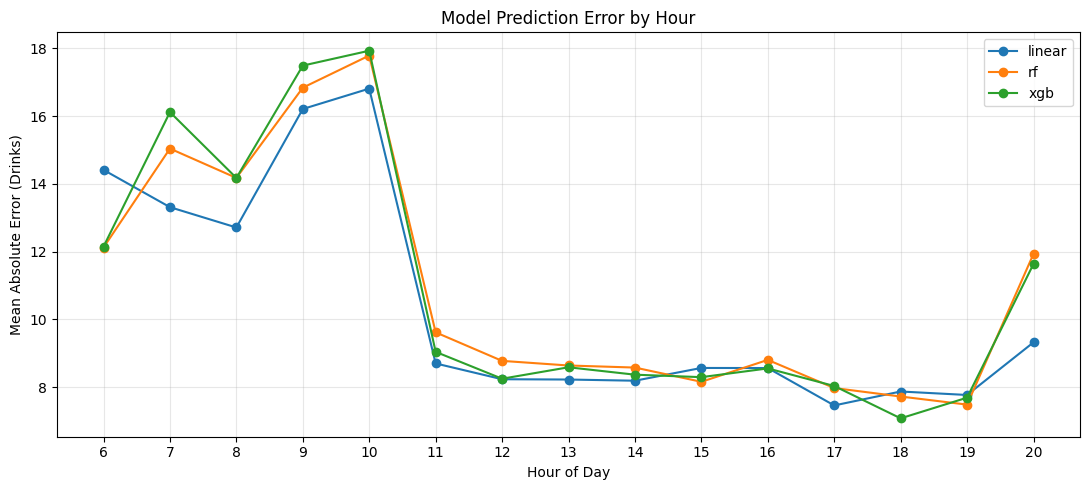

In [39]:
#visualize by hour
plt.figure(figsize=(11, 5))

for column in hourly_errors.columns:
    plt.plot(
        hourly_errors.index,
        hourly_errors[column],
        marker="o",
        label=column.replace("_error", "")
    )

plt.title("Model Prediction Error by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Mean Absolute Error (Drinks)")
plt.xticks(hourly_errors.index)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


All three models struggle most during the café's busiest morning hours, particularly 9–10 AM.
We need to distinguish two types of error: absolute and signed.

In [40]:

# + error = overprediction
# - error = underprediction
error_df["linear_signed_error"] = (
    error_df["linear_pred"] -
    error_df["drinks_sold"]
)

hourly_diagnostics = (
    error_df.groupby("hour")
    .agg(
        observations=("drinks_sold", "size"),
        actual_mean=("drinks_sold", "mean"),
        predicted_mean=("linear_pred", "mean"),
        bias=("linear_signed_error", "mean"),
        MAE=("linear_error", "mean")
    )
)

print(hourly_diagnostics.round(2).to_string())


      observations  actual_mean  predicted_mean  bias    MAE
hour                                                        
6               17        40.65           35.73 -4.91  14.41
7               53        49.17           43.48 -5.69  13.31
8               80        52.51           45.69 -6.82  12.71
9               80        52.81           45.93 -6.88  16.21
10              80        55.18           47.13 -8.04  16.81
11              93        27.88           26.46 -1.42   8.70
12              93        25.87           24.94 -0.93   8.23
13              90        27.07           25.02 -2.04   8.22
14              90        26.38           25.28 -1.10   8.19
15              90        27.67           25.77 -1.90   8.57
16              90        26.69           25.55 -1.14   8.56
17              90        26.80           25.51 -1.29   7.46
18              89        23.06           22.53 -0.53   7.87
19              62        25.89           24.63 -1.26   7.77
20               2      

Try linear regression improvement, hypothesis: store location and hour interact

In [41]:
train_v3 = train_df.copy()
val_v3 = val_df.copy()

for data in [train_v3, val_v3]:
    data["store_hour"] = (
        data["store_location"] + "_" +
        data["hour"].astype(str)
    )

print(
    train_v3[
        ["store_location", "hour", "store_hour"]
    ].head()
)

  store_location  hour  store_hour
0        Astoria    11  Astoria_11
1        Astoria    12  Astoria_12
2        Astoria    13  Astoria_13
3        Astoria    14  Astoria_14
4        Astoria    15  Astoria_15


In [42]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

categorical_v3 = [
    "store_hour",
    "day_of_week"
]

numeric_v3 = [
    "month",
    "sales_lag_1d",
    "sales_lag_7d"
]

feature_columns_v3 = categorical_v3 + numeric_v3

preprocessor_v3 = ColumnTransformer([
    (
        "cat",
        OneHotEncoder(handle_unknown="ignore"),
        categorical_v3
    ),
    (
        "num",
        "passthrough",
        numeric_v3
    )
])

linear_model_v3 = Pipeline([
    ("preprocessor", preprocessor_v3),
    ("regressor", LinearRegression())
])

linear_model_v3.fit(
    train_v3[feature_columns_v3],
    y_train
)

linear_pred_v3 = np.maximum(
    linear_model_v3.predict(
        val_v3[feature_columns_v3]
    ),
    0
)

linear_v3_mae = mean_absolute_error(
    y_val, linear_pred_v3
)

linear_v3_rmse = np.sqrt(
    mean_squared_error(y_val, linear_pred_v3)
)

print("Interaction Model MAE:", round(linear_v3_mae, 2))
print("Interaction Model RMSE:", round(linear_v3_rmse, 2))


Interaction Model MAE: 10.0
Interaction Model RMSE: 14.08


In [43]:
interaction_comparison = pd.DataFrame({
    "Model": [
        "Original Linear Regression",
        "Linear Regression + Interaction"
    ],
    "MAE": [
        linear_mae,
        linear_v3_mae
    ],
    "RMSE": [
        linear_rmse,
        linear_v3_rmse
    ]
})

print(interaction_comparison.round(2).to_string(index=False))


                          Model   MAE  RMSE
     Original Linear Regression 10.08 14.13
Linear Regression + Interaction 10.00 14.08


1. Linear regression systematically underpredicts the morning demand
2. Adding the store hour interaction improves our model slightly
Investigate: did the interaction improve morning predictions?

In [44]:
#compare original vs interaction model
diagnostics = val_df[
    ["hour", "drinks_sold"]
].reset_index(drop=True).copy()

diagnostics["original_pred"] = linear_pred
diagnostics["interaction_pred"] = linear_pred_v3

#define morning peak hours
diagnostics["period"] = np.where(
    diagnostics["hour"].between(7, 10),
    "Morning Peak",
    "Other Hours"
)

#calculate absolute errors
diagnostics["original_abs_error"] = abs(
    diagnostics["original_pred"] - diagnostics["drinks_sold"]
)

diagnostics["interaction_abs_error"] = abs(
    diagnostics["interaction_pred"] - diagnostics["drinks_sold"]
)

#calculate signed errors
diagnostics["original_bias"] = (
    diagnostics["original_pred"] - diagnostics["drinks_sold"]
)

diagnostics["interaction_bias"] = (
    diagnostics["interaction_pred"] - diagnostics["drinks_sold"]
)

peak_comparison = diagnostics.groupby("period").agg(
    observations=("drinks_sold", "size"),
    original_MAE=("original_abs_error", "mean"),
    interaction_MAE=("interaction_abs_error", "mean"),
    original_bias=("original_bias", "mean"),
    interaction_bias=("interaction_bias", "mean")
)

print(peak_comparison.round(2).to_string())


              observations  original_MAE  interaction_MAE  original_bias  interaction_bias
period                                                                                    
Morning Peak           293         14.89            15.06          -6.97             -7.54
Other Hours            806          8.33             8.16          -1.36             -1.52


1. Interaction feature helps during quieter periods, for non-peak hours, MAE decreased from 8.33 to 8.16. This explains why the interaction model achieved a slightly better overall MAE of 10.00.
2. Morning MAE actually increased from 14.89 to 15.06, and the negative bias became more severe. The interaction model underpredicts morning sales by approximately 7.54 drinks per store-hour on average.

In [45]:

from sklearn.base import clone
from sklearn.metrics import mean_absolute_error
import numpy as np
import pandas as pd

cv_df = model_df.copy()

cv_df["store_hour"] = (
    cv_df["store_location"] + "_" +
    cv_df["hour"].astype(str)
)

folds = [
    ("March", "2023-03-01", "2023-04-01"),
    ("April", "2023-04-01", "2023-05-01"),
    ("May", "2023-05-01", "2023-06-01")
]

models = [
    ("Original Linear", linear_model, feature_columns),
    ("Interaction Linear", linear_model_v3, feature_columns_v3)
]

results = []

for month, start, end in folds:

    train = cv_df[
        cv_df["transaction_date"] < start
    ]

    val = cv_df[
        (cv_df["transaction_date"] >= start) &
        (cv_df["transaction_date"] < end)
    ]

    for name, model, columns in models:

        #fresh model for each validation month
        fitted = clone(model)

        fitted.fit(
            train[columns],
            train["drinks_sold"]
        )

        pred = np.maximum(
            fitted.predict(val[columns]),
            0
        )

        actual = val["drinks_sold"].to_numpy()
        morning = val["hour"].between(7, 10).to_numpy()

        results.append({
            "Month": month,
            "Model": name,
            "Overall MAE": mean_absolute_error(actual, pred),
            "Morning MAE": mean_absolute_error(
                actual[morning], pred[morning]
            ),
            "Morning Bias": np.mean(
                pred[morning] - actual[morning]
            )
        })

cv_results = pd.DataFrame(results)

print(cv_results.round(2).to_string(index=False))


Month              Model  Overall MAE  Morning MAE  Morning Bias
March    Original Linear         7.01         9.76         -1.13
March Interaction Linear         6.90         9.69         -1.31
April    Original Linear         8.34        12.21         -3.80
April Interaction Linear         8.24        12.23         -4.16
  May    Original Linear        10.08        14.89         -6.97
  May Interaction Linear        10.00        15.06         -7.54


In [46]:

cv_summary = (
    cv_results.groupby("Model")[
        ["Overall MAE", "Morning MAE", "Morning Bias"]
    ]
    .mean()
)

print(
    cv_summary.round(2).to_string()
)


                    Overall MAE  Morning MAE  Morning Bias
Model                                                     
Interaction Linear         8.38        12.33         -4.34
Original Linear            8.47        12.29         -3.97


Intereaction model -> slightly better, average MAE is 8.38 compared with 8.47 for the original model, an improvement of approximately 1.1%
The original model remains slightly better during morning hours. Morning MAE is 12.29 versus 12.33. More importantly, the original model has less negative morning bias.

In [47]:
print(
    cv_results
    .sort_values(["Month", "Model"])
    .round(2)
    .to_string(index=False)
)

Month              Model  Overall MAE  Morning MAE  Morning Bias
April Interaction Linear         8.24        12.23         -4.16
April    Original Linear         8.34        12.21         -3.80
March Interaction Linear         6.90         9.69         -1.31
March    Original Linear         7.01         9.76         -1.13
  May Interaction Linear        10.00        15.06         -7.54
  May    Original Linear        10.08        14.89         -6.97


In [49]:
hourly_history = pd.read_csv(
    "../data/processed/hourly_sales.csv",
    parse_dates=["transaction_date"]
)

rolling_df = model_df.copy()

#match sales from the previous 7 calendar days
for days in range(1, 8):
    previous = hourly_history[
        ["transaction_date", "store_location",
         "hour", "drinks_sold"]
    ].copy()

    previous["transaction_date"] += pd.Timedelta(days=days)

    previous = previous.rename(
        columns={"drinks_sold": f"lag_{days}"}
    )

    rolling_df = rolling_df.merge(
        previous,
        on=["transaction_date", "store_location", "hour"],
        how="left",
        validate="one_to_one"
    )

#calculate recent average
lag_columns = [f"lag_{d}" for d in range(1, 8)]

rolling_df["rolling_mean_7d"] = (
    rolling_df[lag_columns].mean(axis=1)
)

rolling_df["rolling_count_7d"] = (
    rolling_df[lag_columns].notna().sum(axis=1)
)

print(
    rolling_df[
        ["transaction_date", "store_location", "hour",
         "rolling_mean_7d", "rolling_count_7d"]
    ].head(10).to_string(index=False)
)


transaction_date store_location  hour  rolling_mean_7d  rolling_count_7d
      2023-01-08        Astoria    11        23.142857                 7
      2023-01-08        Astoria    12        34.428571                 7
      2023-01-08        Astoria    13        29.142857                 7
      2023-01-08        Astoria    14        22.428571                 7
      2023-01-08        Astoria    15        26.285714                 7
      2023-01-08        Astoria    16        23.857143                 7
      2023-01-08        Astoria    17        22.285714                 7
      2023-01-08        Astoria    18        29.285714                 7
      2023-01-08        Astoria    19        23.142857                 7
      2023-01-08 Hell's Kitchen     8        26.714286                 7


In [50]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error

numeric_rolling = [
    "month",
    "sales_lag_1d",
    "sales_lag_7d",
    "rolling_mean_7d"
]

rolling_features = categorical_features + numeric_rolling

rolling_preprocessor = ColumnTransformer([
    (
        "cat",
        OneHotEncoder(handle_unknown="ignore"),
        categorical_features
    ),
    (
        "num",
        "passthrough",
        numeric_rolling
    )
])

rolling_model = Pipeline([
    ("preprocessor", rolling_preprocessor),
    ("regressor", LinearRegression())
])

#same chronological training/validation split
rolling_train = rolling_df[
    rolling_df["transaction_date"] < "2023-05-01"
]

rolling_val = rolling_df[
    (rolling_df["transaction_date"] >= "2023-05-01") &
    (rolling_df["transaction_date"] < "2023-06-01")
]

rolling_model.fit(
    rolling_train[rolling_features],
    rolling_train["drinks_sold"]
)

rolling_pred = np.maximum(
    rolling_model.predict(rolling_val[rolling_features]),
    0
)

rolling_mae = mean_absolute_error(
    rolling_val["drinks_sold"], rolling_pred
)

rolling_rmse = np.sqrt(
    mean_squared_error(
        rolling_val["drinks_sold"], rolling_pred
    )
)

print("Rolling Model MAE:", round(rolling_mae, 2))
print("Rolling Model RMSE:", round(rolling_rmse, 2))

Rolling Model MAE: 9.97
Rolling Model RMSE: 13.88


In [51]:
comparison = pd.DataFrame({
    "Model": [
        "Original Linear Regression",
        "Linear + Rolling Average"
    ],
    "MAE": [
        linear_mae,
        rolling_mae
    ],
    "RMSE": [
        linear_rmse,
        rolling_rmse
    ]
})

print(comparison.round(2).to_string(index=False))

                     Model   MAE  RMSE
Original Linear Regression 10.08 14.13
  Linear + Rolling Average  9.97 13.88


In [52]:
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error
import numpy as np
import pandas as pd

folds = [
    ("March", "2023-03-01", "2023-04-01"),
    ("April", "2023-04-01", "2023-05-01"),
    ("May", "2023-05-01", "2023-06-01")
]

models = [
    ("Original Linear", linear_model, feature_columns),
    ("Rolling Linear", rolling_model, rolling_features)
]

cv_rolling_results = []

for month, start, end in folds:

    train = rolling_df[
        rolling_df["transaction_date"] < start
    ]

    val = rolling_df[
        (rolling_df["transaction_date"] >= start) &
        (rolling_df["transaction_date"] < end)
    ]

    for name, model, columns in models:

        fitted = clone(model)

        fitted.fit(
            train[columns],
            train["drinks_sold"]
        )

        predictions = np.maximum(
            fitted.predict(val[columns]),
            0
        )

        actual = val["drinks_sold"].to_numpy()
        morning = val["hour"].between(7, 10).to_numpy()

        cv_rolling_results.append({
            "Month": month,
            "Model": name,
            "Overall MAE": mean_absolute_error(
                actual, predictions
            ),
            "Morning MAE": mean_absolute_error(
                actual[morning],
                predictions[morning]
            ),
            "Morning Bias": np.mean(
                predictions[morning] - actual[morning]
            )
        })

cv_rolling_results = pd.DataFrame(cv_rolling_results)
print(cv_rolling_results.round(2).to_string(index=False))

Month           Model  Overall MAE  Morning MAE  Morning Bias
March Original Linear         7.01         9.76         -1.13
March  Rolling Linear         6.97         9.73         -0.60
April Original Linear         8.34        12.21         -3.80
April  Rolling Linear         8.25        12.04         -3.10
  May Original Linear        10.08        14.89         -6.97
  May  Rolling Linear         9.97        14.57         -5.78


In [53]:
cv_rolling_summary = (
    cv_rolling_results
    .groupby("Model")[
        ["Overall MAE", "Morning MAE", "Morning Bias"]
    ]
    .mean()
)

print(cv_rolling_summary.round(2).to_string())

                 Overall MAE  Morning MAE  Morning Bias
Model                                                  
Original Linear         8.47        12.29         -3.97
Rolling Linear          8.40        12.11         -3.16


Incorporating recent historical demand through a seven-day rolling average can improve short-term café demand forecasting, including reducing systematic underprediction during morning peak hours.

In [54]:
#work with historical data before June
history = hourly_history[
    hourly_history["transaction_date"] < "2023-06-01"
].copy()

usable = model_df[
    model_df["transaction_date"] < "2023-06-01"
][
    ["transaction_date", "store_location", "hour"]
].copy()

#mark which hourly observations remain in our model dataset
coverage_df = history.merge(
    usable.assign(usable=True),
    on=["transaction_date", "store_location", "hour"],
    how="left",
    validate="one_to_one"
)

coverage_df["usable"] = (
    coverage_df["usable"].fillna(False)
)

#calculate retention rate by hour
hourly_coverage = (
    coverage_df.groupby("hour")["usable"]
    .agg(
        total="size",
        retained="sum",
        retention_rate="mean"
    )
)

hourly_coverage["retention_rate"] *= 100

print(hourly_coverage.round(2).to_string())


      total retained retention_rate
hour                               
6       159       81      50.943396
7       344      248      72.093023
8       423      374      88.416076
9       423      374      88.416076
10      423      374      88.416076
11      453      432      95.364238
12      452      429      94.911504
13      447      415      92.841163
14      448      418      93.303571
15      447      415      92.841163
16      448      418      93.303571
17      447      415      92.841163
18      446      413      92.600897
19      315      288      91.428571
20       49       10      20.408163


Midday coverage is strong. Between 11 AM and 6 PM, approximately 93–95% of recorded store-hours were retained. Our model has relatively complete historical data for these periods.
Morning peak coverage is reasonable, but not perfect. Between 8 AM and 10 AM, 88.4% of observations were retained. Because morning demand is our most difficult prediction period, we should report this limitation.

Final June Test Evaluation, our selected model: Linear regression + 7-day rolling average

In [55]:

from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

#final chronological split
train_final = rolling_df[
    rolling_df["transaction_date"] < "2023-06-01"
].copy()

test_final = rolling_df[
    (rolling_df["transaction_date"] >= "2023-06-01") &
    (rolling_df["transaction_date"] < "2023-07-01")
].copy()

print("Training:", len(train_final))
print("Testing:", len(test_final))

#ensure training precedes testing
assert train_final["transaction_date"].max() < \
       test_final["transaction_date"].min()

#retrain the selected model on Jan-May
final_model = clone(rolling_model)

final_model.fit(
    train_final[rolling_features],
    train_final["drinks_sold"]
)

#predict June sales
y_test = test_final["drinks_sold"].to_numpy()

final_pred = np.maximum(
    final_model.predict(test_final[rolling_features]),
    0
)

print(
    "Final Test MAE:",
    round(mean_absolute_error(y_test, final_pred), 2)
)

print(
    "Final Test RMSE:",
    round(np.sqrt(mean_squared_error(y_test, final_pred)), 2)
)

Training: 5104
Testing: 1060
Final Test MAE: 10.9
Final Test RMSE: 14.78


In [57]:
#retrain original Linear Regression
original_final = clone(linear_model)

original_final.fit(
    train_final[feature_columns],
    train_final["drinks_sold"]
)

original_pred = np.maximum(
    original_final.predict(test_final[feature_columns]),
    0
)

#simple recent-sales baseline
weighted_pred = (
    0.7 * test_final["sales_lag_1d"].to_numpy() +
    0.3 * test_final["sales_lag_7d"].to_numpy()
)

#define morning peak period
morning = test_final["hour"].between(7, 10).to_numpy()

predictions = {
    "Weighted Average": weighted_pred,
    "Original Linear": original_pred,
    "Rolling Linear": final_pred
}

results = []

for name, pred in predictions.items():
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "Morning MAE": mean_absolute_error(
            y_test[morning], pred[morning]
        ),
        "Morning Bias": np.mean(
            pred[morning] - y_test[morning]
        )
    })

final_comparison = pd.DataFrame(results)

print(
    final_comparison.round(2).to_string(index=False)
)

           Model   MAE  RMSE  Morning MAE  Morning Bias
Weighted Average 11.67 16.11        17.33         -0.01
 Original Linear 11.02 14.91        15.97         -4.05
  Rolling Linear 10.90 14.78        15.73         -3.14


Selected model achieves:
- approx. 6.6% lower overall MAE than the weighted-average baseline.
- approx. 1.1% lower overall MAE than the original Linear Regression.
- approx. 1.5% lower morning MAE than the original Linear Regression.

Our selected model has a morning bias of −3.14, meaning it underpredicts morning sales by approximately 3.14 drinks per store-hour on average.
Meanwhile, the weighted-average baseline has a bias of −0.01, almost zero.
For staffing decisions, we may eventually need to consider asymmetric costs: underpredicting 15 drinks during a rush could be more consequential than overpredicting 15 drinks.

A Linear Regression model incorporating calendar information, store location, historical sales, and seven-day rolling demand achieves better short-term beverage sales forecasting accuracy than the evaluated historical baselines and initial tree-based models. Rolling-average features provide a modest but consistent improvement across multiple validation periods and the final June test.

Limitations
- The dataset represents synthetic transaction records, not necessarily actual customer demand.
- The model requires historical observations and currently excludes store-hours without complete lag features.
- The final metrics apply to a rolling one-day-ahead forecast, not a forecast made a month in advance.
- We used June as the final holdout, so further changes should be evaluated on new holdout data rather than repeatedly tuning against June.

In [59]:
from pathlib import Path
import joblib

joblib.dump(
    final_model,
    "../models/cafe_demand_model.joblib"
)

print("Model saved successfully!")


Model saved successfully!


In [ ]:

import json
model_metadata = {
    "model_name": "Linear Regression with 7-Day Rolling Average",
    "features": rolling_features,
    "target": "drinks_sold",
    "forecast_horizon": "one_day_ahead",
    "training_period": "2023-01-08 to 2023-05-31",
    "test_period": "2023-06-01 to 2023-06-30",
    "test_mae": 10.90,
    "test_rmse": 14.78,
    "notes": "Requires actual historical beverage sales; excludes missing-lag observations."
}

with open("../models/model_metadata.json", "w") as f:
    json.dump(model_metadata, f, indent=4)

print("Metadata saved!")


In [ ]:
loaded_model = joblib.load(
    "../models/cafe_demand_model.joblib"
)
loaded_pred = loaded_model.predict(
    test_final[rolling_features].head(5)
)

print("Sample predictions:", np.maximum(loaded_pred, 0))
